# Experiment 16 — SHAP-guided feature selection for AutoGluon

Rank the full 36-feature space with CatBoost TreeSHAP, evaluated on the recent outer-period feature distribution. Then fit the actual AutoGluon GBM + CatBoost ensemble on several top-K SHAP subsets and compare them with the manually selected Exp 9 feature set and the complete feature set. The outer period intentionally selects the subset because it is closest to the test horizon.

SHAP values are produced by a dedicated CatBoost selector rather than approximating the complete weighted AutoGluon ensemble. Every proposed subset is therefore validated by retraining the real AutoGluon ensemble.

**Executed result:** the SHAP top-18 subset scored **RMSE 467.841**, **MAE 339.549**, and **R² 0.4929**, versus **468.272** for the manual 18-feature comparator in the same shortened run. Top-22 scored **468.721**, all 36 features **468.921**, and top-10/top-14 about **473.27/473.00**. The 0.431 gain is promising but was selected on the same outer period, so it is not an untouched estimate and did not replace the active production feature set.

In [1]:
from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from autogluon.tabular import TabularPredictor
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
roots = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (root for root in roots if (root / 'exploration' / 'metul' / 'preprocessing.py').exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
sys.path.insert(0, str(project_root / 'exploration' / 'metul'))

source_notebook = json.loads(
    (project_root / 'exploration' / 'metul' / 'exp_14_resale_features_lgbm.ipynb').read_text()
)
source_cells = {
    cell.get('metadata', {}).get('id'): ''.join(cell.get('source', []))
    for cell in source_notebook['cells']
}
exec(source_cells['setup'], globals())
exec(source_cells['exp9-best-feature-transformer'], globals())

RANDOM_STATE = 42
SHAP_SAMPLE_SIZE = int(os.environ.get('EXP16_SHAP_SAMPLE_SIZE', '5000'))
SHAP_CATBOOST_ITERATIONS = int(os.environ.get('EXP16_SHAP_ITERATIONS', '700'))
AUTOGLUON_TIME_LIMIT = int(os.environ.get('EXP16_SHAP_AG_TIME_LIMIT', '180'))
PRODUCTION_TIME_LIMIT = int(os.environ.get('EXP16_SHAP_PRODUCTION_TIME_LIMIT', '600'))
TOP_K_VALUES = [10, 14, 18, 22, 28]
HYPERPARAMETERS = {'GBM': {}, 'CAT': {}}
RUN_ID = os.environ.get('EXP16_SHAP_RUN_ID', pd.Timestamp.now().strftime('%Y%m%d_%H%M%S'))
output_root = project_root / 'exploration' / 'metul' / 'ag_exp_16_shap' / RUN_ID
print(f'Experiment output: {output_root}')

Experiment output: /Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_16_shap/20261016_201056


In [2]:
_, datasets = load_datasets(project_root / 'data')
raw = datasets['train'].copy()
raw['period'] = pd.to_datetime(
    raw['RENT_APPROVAL_DATE'] + '-01'
).dt.to_period('M')
periods = np.sort(raw['period'].unique())
outer_cutoff = periods[int(len(periods) * 0.80)]
raw_selection_train = raw.loc[raw['period'] < outer_cutoff].copy()
raw_selection_valid = raw.loc[raw['period'] >= outer_cutoff].copy()
display(pd.DataFrame([
    {'partition': 'SHAP/AutoGluon training', 'rows': len(raw_selection_train), 'first_period': raw_selection_train.period.min(), 'last_period': raw_selection_train.period.max()},
    {'partition': 'outer subset-selection period', 'rows': len(raw_selection_valid), 'first_period': raw_selection_valid.period.min(), 'last_period': raw_selection_valid.period.max()},
]))

,partition,rows,first_period,last_period
0,SHAP/AutoGluon training,117988,2021-01,2024-04
1,outer subset-selection period,32012,2024-05,2025-03


In [3]:
def make_exp16_features(raw_history, raw_future):
    preprocessor = RentalPreprocessor(datasets)
    history_base = preprocessor.fit_transform(
        raw_history.drop(columns=['period', TARGET], errors='ignore')
    )
    future_base = preprocessor.transform(
        raw_future.drop(columns=['period', TARGET], errors='ignore')
    )
    history_best, future_best = make_exp9_best_features(
        raw_history, raw_future, history_base, future_base
    )
    remaining_features = [
        column for column in history_base.columns if column not in BEST_FEATURES
    ]
    candidate_features = BEST_FEATURES + remaining_features
    history_x = pd.concat([
        history_best.reset_index(drop=True),
        history_base[remaining_features].reset_index(drop=True),
    ], axis=1)
    future_x = pd.concat([
        future_best.reset_index(drop=True),
        future_base[remaining_features].reset_index(drop=True),
    ], axis=1)
    assert list(history_x.columns) == candidate_features
    assert list(future_x.columns) == candidate_features
    return history_x, future_x, candidate_features

selection_train_x, selection_valid_x, candidate_features = make_exp16_features(
    raw_selection_train, raw_selection_valid
)
selection_train_y = raw_selection_train[TARGET].astype(float).reset_index(drop=True)
selection_valid_y = raw_selection_valid[TARGET].astype(float).reset_index(drop=True)
print(f'Full candidate set: {len(candidate_features)} features')
display(pd.DataFrame({
    'feature': candidate_features,
    'in_manual_exp9_set': [feature in BEST_FEATURES for feature in candidate_features],
    'dtype': [str(selection_train_x[feature].dtype) for feature in candidate_features],
}))

[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces


,feature,in_manual_exp9_set,dtype
0,TOWN,True,string
1,BLOCK,True,string
2,STREET,True,string
3,FLAT_TYPE,True,string
4,FLAT_MODEL,True,string
5,FLOOR_AREA_SQM,True,float64
6,approval_date_num,True,int64
7,approval_month,True,int64
8,coe_quota_premium_mean,True,float64
9,YEAR_COMPLETED,True,int64


In [4]:
def prepare_catboost_frame(frame, features):
    result = frame[features].copy()
    categorical = result.select_dtypes(
        include=['object', 'string', 'category']
    ).columns.tolist()
    for column in categorical:
        result[column] = result[column].astype('string').fillna('__missing__').astype(str)
    return result, categorical

catboost_train_x, categorical_features = prepare_catboost_frame(
    selection_train_x, candidate_features
)
catboost_valid_x, valid_categorical_features = prepare_catboost_frame(
    selection_valid_x, candidate_features
)
assert categorical_features == valid_categorical_features
selector = CatBoostRegressor(
    iterations=SHAP_CATBOOST_ITERATIONS,
    depth=8,
    learning_rate=0.05,
    loss_function='RMSE',
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    verbose=100,
)
selector.fit(
    Pool(catboost_train_x, label=selection_train_y, cat_features=categorical_features)
)
selector_valid_prediction = selector.predict(catboost_valid_x)
print(
    f'CatBoost selector outer RMSE: '
    f'{mean_squared_error(selection_valid_y, selector_valid_prediction) ** 0.5:.6f}'
)

sample_size = min(SHAP_SAMPLE_SIZE, len(catboost_valid_x))
sample_indices = catboost_valid_x.sample(
    n=sample_size, random_state=RANDOM_STATE
).index
shap_pool = Pool(
    catboost_valid_x.loc[sample_indices],
    cat_features=categorical_features,
)
# CatBoost returns one SHAP column per feature plus the expected value as the final column.
shap_matrix = selector.get_feature_importance(shap_pool, type='ShapValues')
assert shap_matrix.shape[1] == len(candidate_features) + 1
shap_feature_values = shap_matrix[:, :-1]
shap_ranking = pd.DataFrame({
    'feature': candidate_features,
    'mean_abs_SHAP': np.abs(shap_feature_values).mean(axis=0),
    'mean_signed_SHAP': shap_feature_values.mean(axis=0),
    'in_manual_exp9_set': [feature in BEST_FEATURES for feature in candidate_features],
}).sort_values('mean_abs_SHAP', ascending=False).reset_index(drop=True)
shap_ranking['rank'] = np.arange(1, len(shap_ranking) + 1)
display(shap_ranking)

0:	learn: 715.7430083	total: 88.9ms	remaining: 1m 2s
100:	learn: 481.7271649	total: 3.15s	remaining: 18.7s
200:	learn: 476.5813702	total: 6.09s	remaining: 15.1s
300:	learn: 473.3218330	total: 9.2s	remaining: 12.2s
400:	learn: 470.4044545	total: 12.5s	remaining: 9.29s
500:	learn: 467.4816533	total: 15.6s	remaining: 6.19s
600:	learn: 464.5422933	total: 18.8s	remaining: 3.1s
699:	learn: 461.7948104	total: 22.1s	remaining: 0us
CatBoost selector outer RMSE: 536.592229


,feature,mean_abs_SHAP,mean_signed_SHAP,in_manual_exp9_set,rank
0,town_flat_type_target_mean,223.736795,203.207591,True,1
1,approval_date_num,101.737671,101.737671,True,2
2,FLAT_TYPE,61.788139,-15.425150,True,3
3,RENT_APPROVAL_DATE,50.779692,-50.778738,False,4
4,FLOOR_AREA_SQM,48.041529,-1.014334,True,5
5,mrt_dist_nearest_km,32.585071,-0.453034,True,6
6,STREET,28.272043,0.495332,True,7
7,coe_quota_premium_mean,24.030994,24.030994,True,8
8,LATITUDE,22.630478,1.418844,False,9
9,LEASE_COMMENCE_DATE,20.356566,3.935775,False,10


,features,median_rank,total_mean_abs_SHAP
in_manual_exp9_set,,,
False,18,25.5,203.559373
True,18,15.5,623.772864


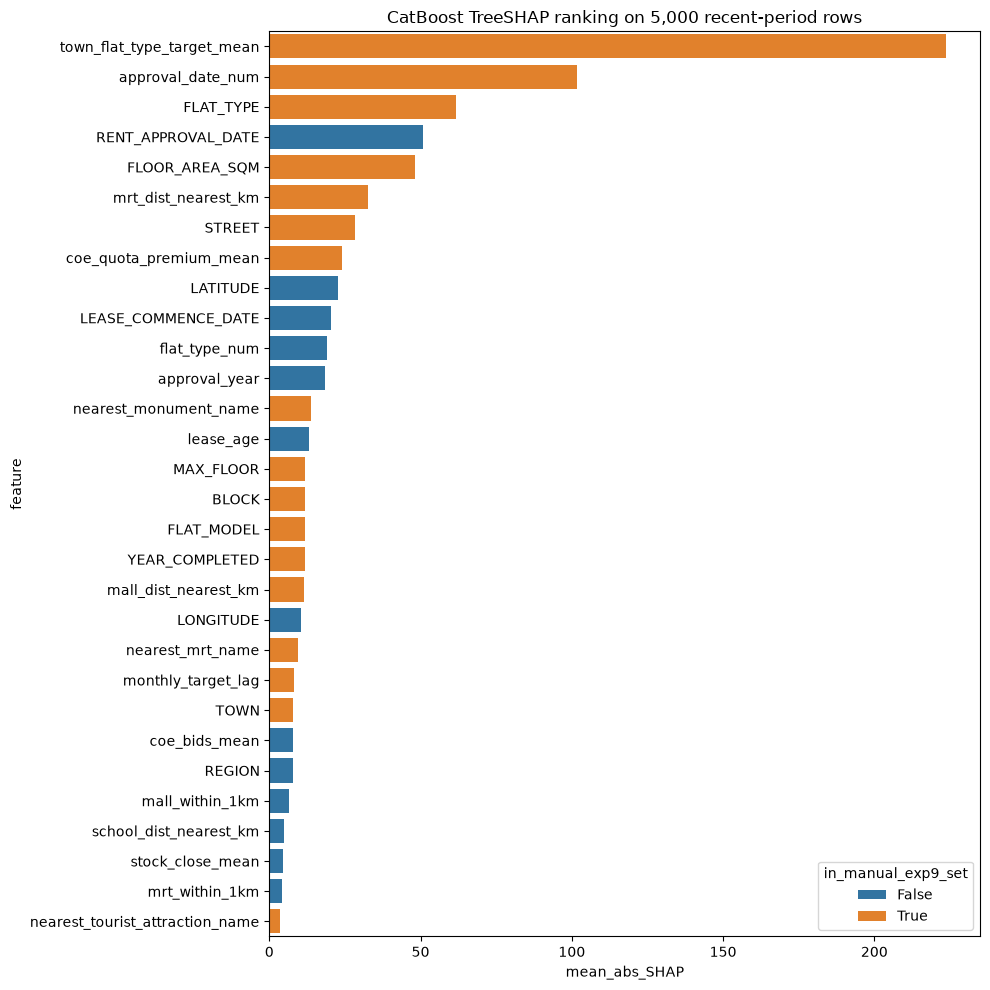

In [5]:
plt.figure(figsize=(10, 10))
sns.barplot(
    data=shap_ranking.head(30),
    x='mean_abs_SHAP',
    y='feature',
    hue='in_manual_exp9_set',
    dodge=False,
)
plt.title(f'CatBoost TreeSHAP ranking on {sample_size:,} recent-period rows')
plt.tight_layout()

manual_rank_summary = shap_ranking.groupby('in_manual_exp9_set').agg(
    features=('feature', 'size'),
    median_rank=('rank', 'median'),
    total_mean_abs_SHAP=('mean_abs_SHAP', 'sum'),
)
display(manual_rank_summary)

In [6]:
def fit_autogluon(train_x, train_y, features, path, time_limit):
    train_data = train_x[features].copy()
    train_data[TARGET] = train_y.to_numpy()
    return TabularPredictor(
        label=TARGET,
        problem_type='regression',
        eval_metric='root_mean_squared_error',
        path=str(path),
    ).fit(
        train_data=train_data,
        hyperparameters=HYPERPARAMETERS,
        presets=['medium_quality', 'ignore_text'],
        time_limit=time_limit,
        verbosity=2,
    )

ranked_features = shap_ranking['feature'].tolist()
subset_candidates = {
    **{f'shap_top_{k}': ranked_features[:k] for k in TOP_K_VALUES},
    'manual_exp9_best': BEST_FEATURES.copy(),
    'all_expanded_features': candidate_features.copy(),
}
selection_rows = []
for subset_name, features in subset_candidates.items():
    print(f'Fitting {subset_name}: {len(features)} features')
    model = fit_autogluon(
        selection_train_x,
        selection_train_y,
        features,
        output_root / f'selection_{subset_name}',
        AUTOGLUON_TIME_LIMIT,
    )
    prediction = model.predict(selection_valid_x[features]).astype(float).to_numpy()
    selection_rows.append({
        'subset': subset_name,
        'feature_count': len(features),
        'outer_RMSE': mean_squared_error(selection_valid_y, prediction) ** 0.5,
        'outer_MAE': mean_absolute_error(selection_valid_y, prediction),
        'outer_R2': r2_score(selection_valid_y, prediction),
        'features': features.copy(),
        'best_model': model.model_best,
    })

shap_subset_results = pd.DataFrame(selection_rows)
best_subset_index = shap_subset_results['outer_RMSE'].idxmin()
selected_subset_name = shap_subset_results.loc[best_subset_index, 'subset']
selected_features = list(shap_subset_results.loc[best_subset_index, 'features'])
display(shap_subset_results.drop(columns='features').sort_values('outer_RMSE'))
print(
    f'Selected {selected_subset_name} with {len(selected_features)} features '
    f'using outer RMSE={shap_subset_results.loc[best_subset_index, "outer_RMSE"]:.6f}'
)
print(selected_features)

Verbosity: 2 (Standard Logging)


Fitting shap_top_10: 10 features


=================== System Info ===================
AutoGluon Version:  1.6.2
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       3.28 GB / 16.00 GB (20.5%)
Disk Space Avail:   166.63 GB / 460.38 GB (36.2%)
Presets specified: ['medium_quality', 'ignore_text']
Beginning AutoGluon training ... Time limit = 180s
AutoGluon will save models to "/Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_16_shap/20261016_201056/selection_shap_top_10"
Train Data Rows:    117988
Train Data Columns: 10
Label Column:       MONTHLY_RENT
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitti

Fitting shap_top_14: 14 features


	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])                      : 5 | ['town_flat_type_target_mean', 'FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'coe_quota_premium_mean', 'LATITUDE']
		('int', [])                        : 5 | ['approval_date_num', 'LEASE_COMMENCE_DATE', 'flat_type_num', 'approval_year', 'lease_age']
		('object', [])                     : 3 | ['FLAT_TYPE', 'STREET', 'nearest_monument_name']
		('object', ['datetime_as_object']) : 1 | ['RENT_APPROVAL_DATE']
	Types of features in processed data (raw dtype, special dtypes):
		('category', [])             : 3 | ['FLAT_TYPE', 'STREET', 'nearest_monument_name']
		('float', [])                : 5 | ['town_flat_type_target_mean', 'FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'coe_quota_premium_mean', 'LATITUDE']
		('int', [])                  : 5 | ['approval_date_num', 'LEAS

...

	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])        : 6 | ['FLOOR_AREA_SQM', 'coe_quota_premium_mean', 'mrt_dist_nearest_km', 'mall_dist_nearest_km', 'monthly_target_lag', ...]
		('int', [])          : 4 | ['approval_date_num', 'approval_month', 'YEAR_COMPLETED', 'MAX_FLOOR']
		('object', [])       : 7 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', ...]
		('object', ['text']) : 1 | ['nearest_mrt_name']
	Types of features in processed data (raw dtype, special dtypes):
		('category', [])                   : 7 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', ...]
		('category', ['text_as_category']) : 1 | ['n

Fitting all_expanded_features: 36 features


	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
		Fitting DatetimeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])                      : 12 | ['FLOOR_AREA_SQM', 'coe_quota_premium_mean', 'mrt_dist_nearest_km', 'mall_dist_nearest_km', 'monthly_target_lag', ...]
		('int', [])                        : 14 | ['approval_date_num', 'approval_month', 'YEAR_COMPLETED', 'MAX_FLOOR', 'LEASE_COMMENCE_DATE', ...]
		('object', [])                     :  8 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', ...]
		('object', ['datetime_as_object']) :  1 | ['RENT_APPROVAL_DATE']
		('object', ['text'])        

,subset,feature_count,outer_RMSE,outer_MAE,outer_R2,best_model
2,shap_top_18,18,467.840906,339.548755,0.492921,WeightedEnsemble_L2
5,manual_exp9_best,18,468.271759,340.986810,0.491986,WeightedEnsemble_L2
3,shap_top_22,22,468.721171,341.248453,0.491011,WeightedEnsemble_L2
6,all_expanded_features,36,468.920991,344.700755,0.490577,WeightedEnsemble_L2
4,shap_top_28,28,469.027886,344.931724,0.490344,WeightedEnsemble_L2
1,shap_top_14,14,472.996995,344.522481,0.481682,WeightedEnsemble_L2
0,shap_top_10,10,473.273642,344.389000,0.481075,WeightedEnsemble_L2


Selected shap_top_18 with 18 features using outer RMSE=467.840906
['town_flat_type_target_mean', 'approval_date_num', 'FLAT_TYPE', 'RENT_APPROVAL_DATE', 'FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'STREET', 'coe_quota_premium_mean', 'LATITUDE', 'LEASE_COMMENCE_DATE', 'flat_type_num', 'approval_year', 'nearest_monument_name', 'lease_age', 'MAX_FLOOR', 'BLOCK', 'FLAT_MODEL', 'YEAR_COMPLETED']
